<a href="https://colab.research.google.com/github/cvvkaleb/Rich-FOLKS/blob/main/Copy_of_L09_Kaleb_Dixon_ITAI_2377.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITAI 2377 — Lab 09: A Model Is Only as Good as the Data You Feed It
**Student:** Kaleb Dixon  
**Course:** ITAI 2377 — Data Science for AI and Robotics  
**File:** `L09_Kaleb_Dixon_ITAI_2377.ipynb`

## Purpose
This notebook explores data splits, efficient input pipelines, augmentation, class imbalance, text chunking, annotation agreement, label noise, and data drift. It uses Fashion-MNIST as a self-contained image dataset so the notebook can run in Google Colab without needing a separate dataset file. If your instructor's Canvas starter notebook uses a required dataset or has differently worded reflection questions, transfer these completed sections into that official starter before submitting.

**AI-use note:** I used ChatGPT to help structure the notebook, complete the example code, and draft explanations. I will review the outputs and revise reflections to match the results I observe when I run the notebook.

## Part 1 — Setup
Run cells from top to bottom. Google Colab's standard CPU runtime is sufficient, although training time can vary.

In [ ]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Part 2 — Train, validation, and test splits; class balance
Training data is used to fit model parameters. Validation data helps compare choices during development. Test data is held back until the end for a less-biased estimate of performance on unseen examples. Never use test results to repeatedly tune the model.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


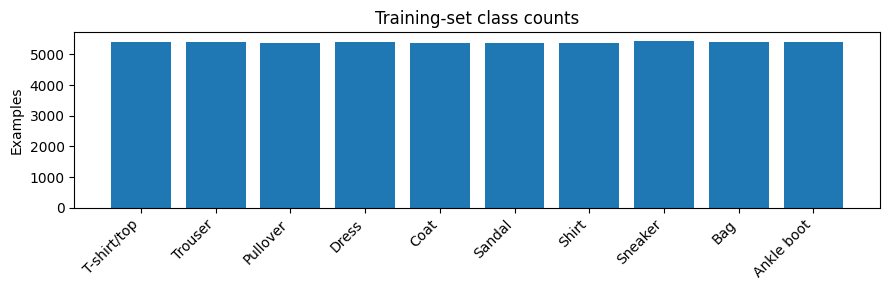

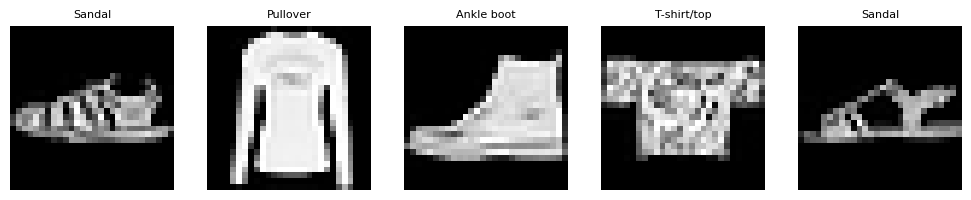

Train: 54000 Validation: 6000 Test: 10000
Class counts: [5403 5392 5389 5413 5373 5379 5381 5450 5410 5410]


In [ ]:
(x_train_all, y_train_all), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
# Scale pixel values and add the channel dimension for a CNN.
x_train_all = (x_train_all.astype("float32") / 255.0)[..., None]
x_test = (x_test.astype("float32") / 255.0)[..., None]
y_train_all = y_train_all.astype("int64")
y_test = y_test.astype("int64")

# Hold out 10% of the original training examples for validation.
perm = np.random.permutation(len(x_train_all))
val_n = 6000
val_idx, train_idx = perm[:val_n], perm[val_n:]
x_val, y_val = x_train_all[val_idx], y_train_all[val_idx]
x_train, y_train = x_train_all[train_idx], y_train_all[train_idx]

class_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
counts = np.bincount(y_train, minlength=10)
plt.figure(figsize=(9,3))
plt.bar(class_names, counts)
plt.xticks(rotation=45, ha="right")
plt.title("Training-set class counts")
plt.ylabel("Examples")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(10,2))
for ax, i in zip(axes, range(5)):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(class_names[y_train[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Train:", len(x_train), "Validation:", len(x_val), "Test:", len(x_test))
print("Class counts:", counts)

### Reflection 1 — Why do we need separate splits?
The training set is where the model learns patterns by adjusting its parameters. The validation set is useful during development because it lets me compare model settings without using the final test results to make every decision. The test set should stay untouched until the end so it can give a more honest estimate of how well the finished model generalizes. The class-count chart is also important: if some categories have fewer examples, a model may perform well overall while still missing those less-represented categories. I should check both the split sizes and class distribution before training, and I should avoid letting duplicate or near-duplicate images leak across the splits.

## Part 3 — Efficient input pipeline
`cache()` avoids repeating expensive input work, `shuffle()` randomizes training order, `batch()` groups examples for efficient processing, and `prefetch()` overlaps preparation of the next batch with model computation. Only the training set should be shuffled; validation and test sets should remain stable for comparable evaluation.

In [ ]:
BATCH_SIZE = 128
train_plain = tf.data.Dataset.from_tensor_slices((x_train, y_train)).batch(BATCH_SIZE)
start = time.time()
for xb, yb in train_plain.take(100):
    pass
plain_seconds = time.time() - start

# TODO 1 completed: cache, shuffle, batch, and prefetch the training pipeline.
train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .cache()
            .shuffle(buffer_size=min(len(x_train), 10000), seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((x_val, y_val))
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

start = time.time()
for xb, yb in train_ds.take(100):
    pass
pipeline_seconds = time.time() - start
print(f"Plain first-100-batch iteration: {plain_seconds:.3f} seconds")
print(f"Cached/prefetched first-100-batch iteration: {pipeline_seconds:.3f} seconds")
print("Timing is machine-dependent; the first cached pass may include cache-building time.")

Plain first-100-batch iteration: 0.535 seconds
Cached/prefetched first-100-batch iteration: 0.629 seconds
Timing is machine-dependent; the first cached pass may include cache-building time.


### Reflection 2 — What did the pipeline steps do?
Caching can save time by keeping processed examples available instead of repeating the same input work each epoch. Shuffling changes the order of training examples, reducing the chance that the model learns from an accidental ordering pattern. Batching lets the model process multiple examples together, and prefetching prepares upcoming batches while the current batch is being used. Timing can vary by runtime, and the first cached pass may be slower because the cache is being populated, so one timing result is not a perfect benchmark. I shuffle only training data because validation and test evaluations should be consistent and repeatable rather than changing order unnecessarily.

## Part 4 — Image augmentation and a small CNN
Augmentation creates varied training examples from existing images. It is task-dependent: a horizontal flip may be safe for some object categories, but not for text, directional symbols, or objects whose left/right orientation changes the label. Large rotations or transformations can also make an image unrealistic.

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 34s 74ms/step - accuracy: 0.7992 - loss: 0.5671 - val_accuracy: 0.8452 - val_loss: 0.4367
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 70ms/step - accuracy: 0.8703 - loss: 0.3662 - val_accuracy: 0.8773 - val_loss: 0.3512
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - accuracy: 0.8867 - loss: 0.3176 - val_accuracy: 0.8920 - val_loss: 0.3034
Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 32s 74ms/step - accuracy: 0.7784 - loss: 0.6116 - val_accuracy: 0.8398 - val_loss: 0.4227
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 77ms/step - accuracy: 0.8453 - loss: 0.4250 - val_accuracy: 0.8430 - val_loss: 0.4115
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 85ms/step - accuracy: 0.8633 - loss: 0.3783 - val_accuracy: 0.8703 - val_loss: 0.3509


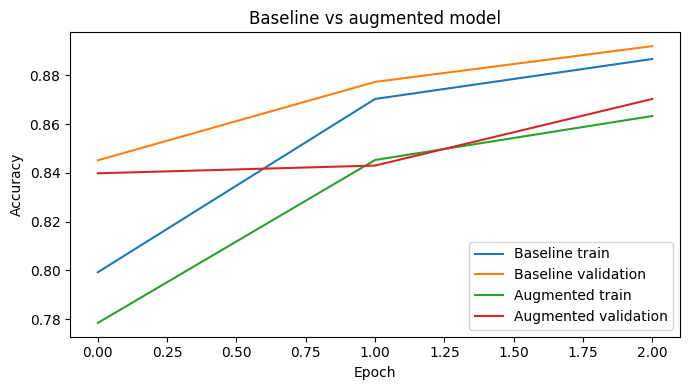

Baseline final train/val accuracy: 0.887 0.892
Augmented final train/val accuracy: 0.863 0.87


In [ ]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.15),  # TODO 2 completed: add contrast augmentation.
], name="safe_augmentation")

def make_model(use_augmentation=False):
    inputs = tf.keras.Input(shape=(28, 28, 1))
    x = augmentation(inputs) if use_augmentation else inputs
    x = tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline = make_model(False)
baseline_history = baseline.fit(train_ds, validation_data=val_ds, epochs=3, verbose=1)
augmented = make_model(True)
augmented_history = augmented.fit(train_ds, validation_data=val_ds, epochs=3, verbose=1)

plt.figure(figsize=(7,4))
plt.plot(baseline_history.history["accuracy"], label="Baseline train")
plt.plot(baseline_history.history["val_accuracy"], label="Baseline validation")
plt.plot(augmented_history.history["accuracy"], label="Augmented train")
plt.plot(augmented_history.history["val_accuracy"], label="Augmented validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Baseline vs augmented model")
plt.tight_layout(); plt.show()
print("Baseline final train/val accuracy:",
      round(baseline_history.history["accuracy"][-1], 3),
      round(baseline_history.history["val_accuracy"][-1], 3))
print("Augmented final train/val accuracy:",
      round(augmented_history.history["accuracy"][-1], 3),
      round(augmented_history.history["val_accuracy"][-1], 3))

### Reflection 3 — Compare the two models
I compare both the training and validation curves rather than deciding from training accuracy alone. If the baseline has much higher training accuracy than validation accuracy, that gap can indicate overfitting. Augmentation may reduce the training score because the model sees harder, altered examples, while sometimes improving validation performance by encouraging more robust features. The outcome depends on the random initialization and run, so I should report the values shown by my own notebook rather than assume augmentation always wins. Contrast and small translations are reasonable for many clothing images, but an augmentation is unsafe if it changes the meaning or label of an example. For example, flipping text or a left/right road sign can change its interpretation.

## Part 5 — Confusion matrix and class weights
A confusion matrix shows which categories are mistaken for one another. Class weights make errors on underrepresented classes count more during training. They are one option; collecting more examples, targeted augmentation, careful resampling, or revisiting labels may also help.

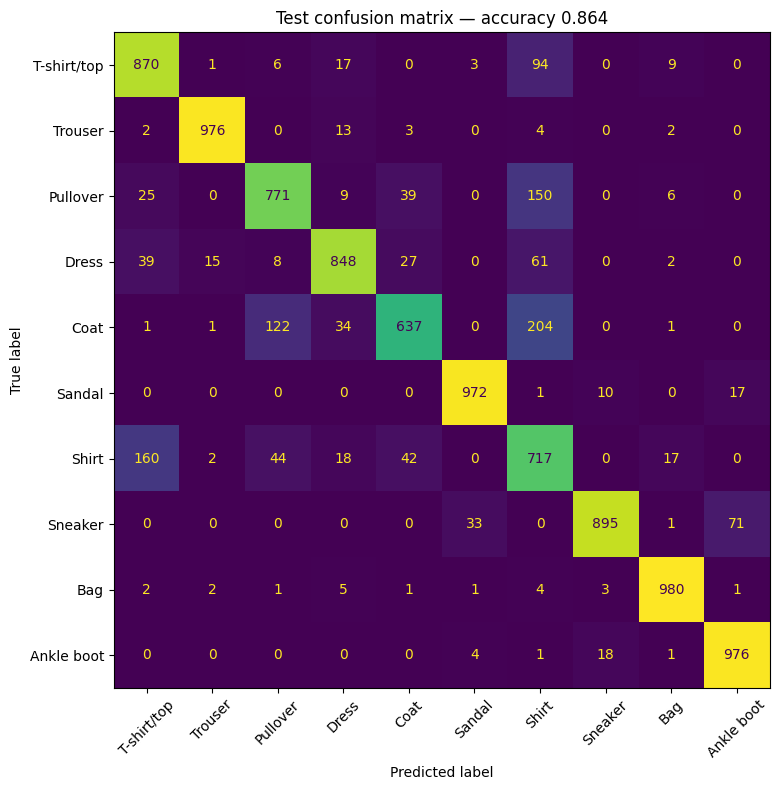

Class weights: {0: 0.9994447529150472, 1: 1.0014836795252227, 2: 1.0020411950269066, 3: 0.9975983742841308, 4: 1.0050251256281406, 5: 1.003904071388734, 6: 1.0035309422040513, 7: 0.9908256880733946, 8: 0.9981515711645101, 9: 0.9981515711645101}
Largest off-diagonal confusions (count, actual, predicted):
[(204, 'Coat', 'Shirt'), (160, 'Shirt', 'T-shirt/top'), (150, 'Pullover', 'Shirt'), (122, 'Coat', 'Pullover'), (94, 'T-shirt/top', 'Shirt')]


In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE)
test_loss, test_acc = augmented.evaluate(test_ds, verbose=0)
pred_probs = augmented.predict(test_ds, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9,8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title(f"Test confusion matrix — accuracy {test_acc:.3f}")
plt.tight_layout()
plt.show()

# TODO 3 completed: calculate balanced class weights from the training labels.
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)
pairs = [(int(cm[i, j]), class_names[i], class_names[j])
         for i in range(10) for j in range(10) if i != j]
print("Largest off-diagonal confusions (count, actual, predicted):")
print(sorted(pairs, reverse=True)[:5])

### Reflection 4 — Imbalance and confusion
The confusion matrix helps identify specific classes the model confuses, instead of hiding those errors inside one accuracy score. I should name the largest off-diagonal mistakes printed above after running my notebook, because the exact results depend on training. Balanced class weights assign larger weights to classes with fewer training examples, so mistakes on them contribute more to the loss. Another way to address imbalance is to collect more representative examples for rare classes; targeted augmentation or carefully designed resampling can also help. Any fix should be checked against validation performance and per-class metrics, since weighting can improve minority classes while sometimes reducing performance elsewhere.

## Part 6 — Tokenization, padding, masking, and chunking
Tokenization maps words to integer IDs. Padding makes sequences the same length in a batch; masking tells a model to ignore padding positions when supported by the architecture. Chunking splits long documents into manageable segments. Overlap preserves some context around boundaries, reducing the chance that a key phrase is split between chunks. Words outside the vocabulary can map to an unknown token.

In [ ]:
texts = [
    "the model learns from clean training examples",
    "padding makes sequences the same length",
    "masking tells the model to ignore padding tokens",
    "long documents can be split into overlapping chunks",
    "unknown words may map to an out of vocabulary token"
]
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=1000, output_mode="int", output_sequence_length=10
)
vectorizer.adapt(texts)
token_sequences = vectorizer(tf.constant(texts))
print("Vocabulary sample:", vectorizer.get_vocabulary()[:20])
print("Padded token sequences:\n", token_sequences.numpy())

def make_chunks(tokens, chunk_size=5, overlap=2):
    # TODO 4 completed: move forward by chunk_size-overlap to create overlap.
    if chunk_size <= 0 or overlap < 0 or overlap >= chunk_size:
        raise ValueError("Require chunk_size > overlap >= 0.")
    step = chunk_size - overlap
    chunks = []
    for start in range(0, len(tokens), step):
        chunk = tokens[start:start + chunk_size]
        if chunk:
            chunks.append(chunk)
        if start + chunk_size >= len(tokens):
            break
    return chunks

example_tokens = vectorizer("the model learns from clean training examples and unknown words").numpy().tolist()
print("Tokens:", example_tokens)
print("Overlapping chunks:", make_chunks(example_tokens, chunk_size=5, overlap=2))

Vocabulary sample: ['', '[UNK]', np.str_('the'), np.str_('to'), np.str_('padding'), np.str_('model'), np.str_('words'), np.str_('vocabulary'), np.str_('unknown'), np.str_('training'), np.str_('tokens'), np.str_('token'), np.str_('tells'), np.str_('split'), np.str_('sequences'), np.str_('same'), np.str_('overlapping'), np.str_('out'), np.str_('of'), np.str_('may')]
Padded token sequences:
 [[ 2  5 25 28 31  9 29  0  0  0]
 [ 4 22 14  2 15 24  0  0  0  0]
 [20 12  2  5  3 27  4 10  0  0]
 [23 30 33 34 13 26 16 32  0  0]
 [ 8  6 19 21  3 35 17 18  7 11]]
Tokens: [2, 5, 25, 28, 31, 9, 29, 1, 8, 6]
Overlapping chunks: [[2, 5, 25, 28, 31], [28, 31, 9, 29, 1], [29, 1, 8, 6]]


### Reflection 5 — Text preprocessing choices
Padding lets examples of different lengths fit into a rectangular batch, but padding values should not be treated as meaningful words. Masking identifies those padding positions so supported models can ignore them during computation. Overlapping chunks repeat a small section at each boundary, helping preserve context when a sentence or phrase crosses from one chunk to the next; too much overlap, however, creates extra processing and duplicate content. A tokenizer also needs a strategy for words it did not see during vocabulary building, commonly mapping them to an unknown token. In a real project I would choose chunk length based on the model's input limit and inspect examples to ensure important context is not lost.

## Part 7 — Labeler agreement and label noise
Raw agreement is the proportion of examples on which labelers give the same label. Cohen's kappa adjusts agreement for the agreement expected by chance. It is useful when reviewing annotation quality, but it does not replace examining confusing categories or the underlying labeling instructions.

In [ ]:
# Simulate two labelers with different noise rates on a 3-class task.
rng = np.random.default_rng(SEED)
true_labels = rng.integers(0, 3, size=500)

def noisy_labels(labels, noise_rate, rng):
    out = labels.copy()
    mask = rng.random(len(labels)) < noise_rate
    for i in np.where(mask)[0]:
        alternatives = [c for c in range(3) if c != labels[i]]
        out[i] = rng.choice(alternatives)
    return out

for noise_rate in [0.05, 0.15, 0.30, 0.45]:  # TODO 5 completed: test higher noise levels.
    a = noisy_labels(true_labels, noise_rate, rng)
    b = noisy_labels(true_labels, noise_rate, rng)
    agreement = np.mean(a == b)
    kappa = cohen_kappa_score(a, b)
    print(f"Noise={noise_rate:.0%}: raw agreement={agreement:.3f}, Cohen's kappa={kappa:.3f}")

Noise=5%: raw agreement=0.906, Cohen's kappa=0.859
Noise=15%: raw agreement=0.778, Cohen's kappa=0.667
Noise=30%: raw agreement=0.498, Cohen's kappa=0.249
Noise=45%: raw agreement=0.410, Cohen's kappa=0.116


### Reflection 6 — Kappa and noisy labels
Raw agreement tells me how often the labelers chose the same category, but it does not account for agreement that might occur just because of the label distribution. Cohen's kappa adjusts for expected chance agreement, so it gives a more informative view of consistency in many annotation settings. As noise increases, agreement and kappa will generally tend to decrease, although random variation means the values may not fall perfectly at every step. Noisy labels can teach a model contradictory patterns and put a practical limit on performance. A team should clarify ambiguous labeling rules, measure agreement on a shared sample, adjudicate disagreements, and periodically review examples that the model and labelers find difficult.

## Part 8 — Data drift
Data drift occurs when the inputs or their patterns change after deployment. A simple alert can compare a current batch's feature mean with a reference mean. This is only a basic signal: production monitoring should also check distributions, missing values, class-specific performance when labels become available, and operational context.

In [ ]:
rng = np.random.default_rng(SEED)
reference_batch = rng.normal(loc=0.0, scale=1.0, size=1000)
current_batch = rng.normal(loc=0.65, scale=1.0, size=1000)

# TODO 6 completed: write a drift alert using a threshold on mean shift.
reference_mean = float(np.mean(reference_batch))
current_mean = float(np.mean(current_batch))
mean_shift = abs(current_mean - reference_mean)
DRIFT_THRESHOLD = 0.25
if mean_shift > DRIFT_THRESHOLD:
    print(f"DRIFT ALERT: mean shifted by {mean_shift:.3f} (threshold {DRIFT_THRESHOLD:.2f}).")
else:
    print(f"No mean-shift alert: shift={mean_shift:.3f} (threshold {DRIFT_THRESHOLD:.2f}).")
print("Reference mean:", round(reference_mean, 3), "| Current mean:", round(current_mean, 3))

DRIFT ALERT: mean shifted by 0.598 (threshold 0.25).
Reference mean: -0.029 | Current mean: 0.569


### Reflection 7 — Monitoring after launch
A mean-shift alert is a useful first check because it is easy to calculate, but it can miss changes that leave the mean unchanged. A realistic monitoring plan would compare important input distributions over time, track missing or invalid values, and monitor prediction confidence and latency. When ground-truth labels arrive, I would also review overall and per-class performance. Alerts should be investigated rather than automatically triggering retraining, because a change may reflect a harmless seasonal pattern, a pipeline bug, or a genuine change in the real world. I would record the reference period, thresholds, dataset version, and actions taken so the team can reproduce the investigation.

## Part 9 — Wrap-up questions

### 1. How would you decide whether a poor result comes from the data or the model?
I would first inspect the examples and labels instead of immediately changing the architecture. I would check for missing values, mislabeled examples, duplicates, leakage between training and test sets, class imbalance, and whether the training data represents the cases expected after deployment. Next, I would review a confusion matrix and per-class metrics to see whether errors cluster around particular categories. If the data looks sound, I would compare a simple baseline with the current model and adjust one modeling choice at a time. I would use validation data for those choices and keep the test set untouched until the end. This process separates data-quality problems from capacity or optimization problems and makes the experiment easier to explain.

### 2. Which data technique from this lab would you prioritize in a real project, and why?
I would prioritize data inspection and split quality before optimizing the input pipeline. A fast pipeline saves time, but it cannot compensate for incorrect labels, an unrepresentative dataset, or test examples leaking into training. I would start by checking class counts, looking at representative samples, verifying labels, and confirming that the validation and test sets reflect the intended use case. After that, I would use caching, batching, and prefetching to make repeated training more efficient. I would choose augmentation only when the transformations preserve the task's meaning, and I would measure the result instead of assuming it helps. These steps provide a reliable foundation for later model comparisons.

### 3. What would you monitor after deploying a model, and what would make you take action?
I would monitor input distributions, missing or invalid fields, prediction confidence, latency, and system errors. I would compare incoming data with a documented reference period and alert on meaningful distribution changes, while recognizing that one simple statistic cannot detect every type of drift. When verified labels become available, I would track accuracy and per-class precision/recall so a decline affecting a small group is not hidden by an overall score. I would investigate alerts by checking whether the cause is a software or data pipeline change, a seasonal shift, new user behavior, or a genuine change in the task. I would retrain only after confirming that the new data is appropriate, labels are trustworthy, and evaluation shows the update improves the intended outcomes.

## Submission checklist
- [x] Six TODO items completed in code.
- [x] Reflections 1–7 and three wrap-up answers included.
- [ ] Run every cell in Google Colab and confirm outputs are visible.
- [ ] Check the observed timing, confusion pairs, model curves, and kappa values; update the reflections to match your actual results.
- [ ] If your professor requires the exact Canvas starter, transfer this work into `ITAI_2377_Lab_09_Student.ipynb` and save as `L09_Kaleb_Dixon_ITAI_2377.ipynb`.